In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [4]:
df=pd.read_csv("student-mat.csv",sep=";")

In [5]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [6]:
df.shape

(395, 33)

In [7]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [9]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [10]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

C. Distribution of final grades

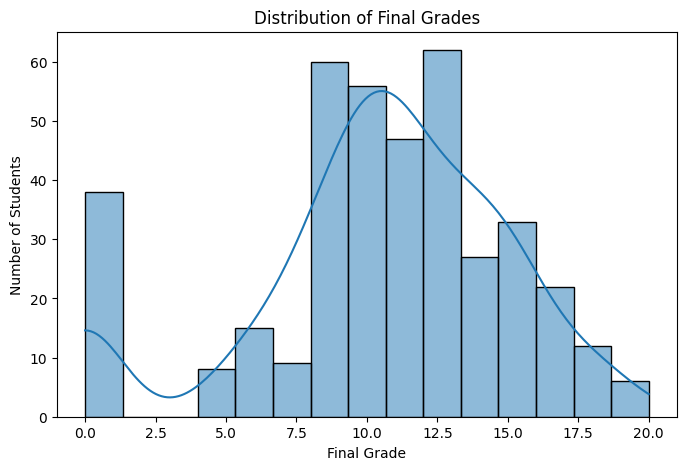

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(df["G3"], bins=15, kde=True)

plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.show()

D. Study time vs final grade

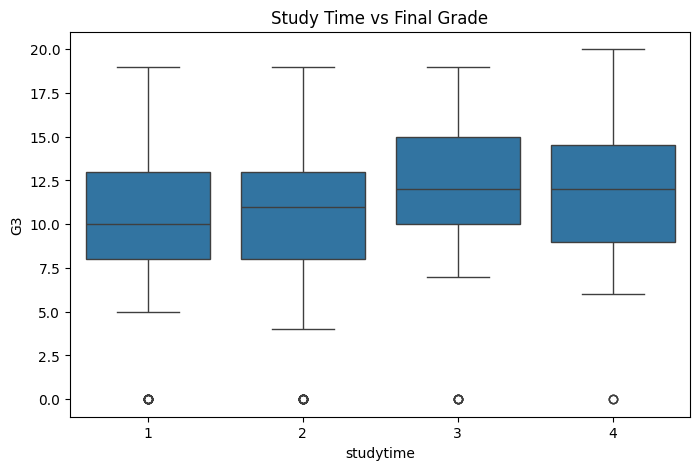

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(x="studytime", y="G3", data=df)

plt.title("Study Time vs Final Grade")
plt.show()

E. Absences vs final grade

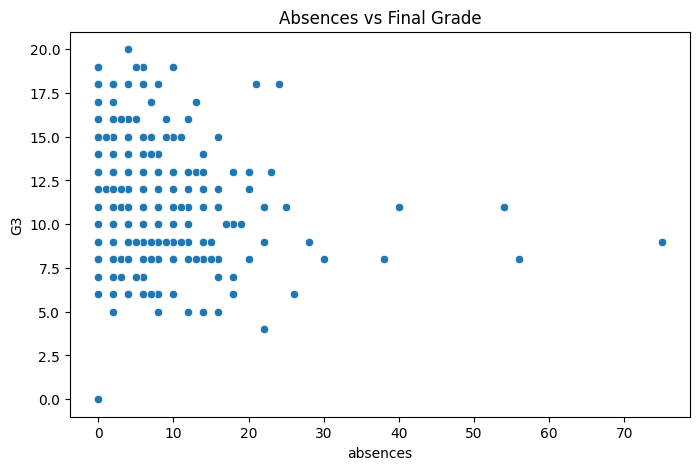

In [14]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x="absences",
    y="G3",
    data=df
)

plt.title("Absences vs Final Grade")
plt.show()

F. Correlation heatmap

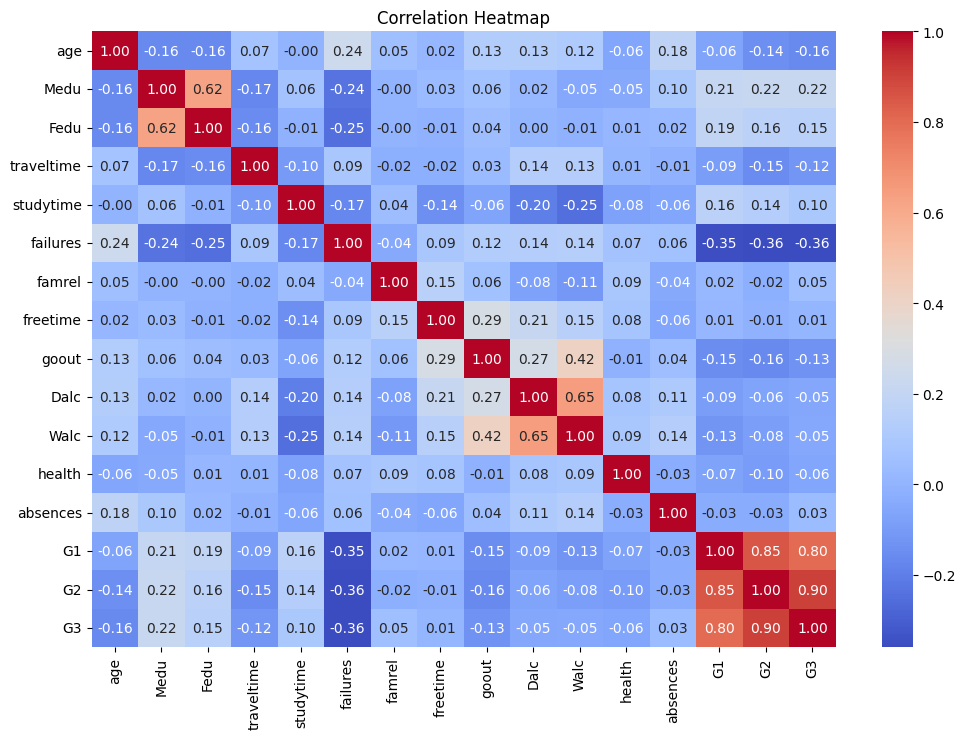

In [15]:
plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

Statistical analysis and outlier detection

A. Central tendency

In [16]:
print("Mean:", df["G3"].mean())
print("Median:", df["G3"].median())
print("Mode:", df["G3"].mode()[0])

Mean: 10.415189873417722
Median: 11.0
Mode: 10


B. Dispersion

In [17]:
print("Variance:", df["G3"].var())
print("Standard Deviation:", df["G3"].std())
print("Range:", df["G3"].max() - df["G3"].min())

Variance: 20.989616397866733
Standard Deviation: 4.5814426109978434
Range: 20


C. IQR method

IQR = Q3 − Q1

In [18]:
Q1 = df["G3"].quantile(0.25)
Q3 = df["G3"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["G3"] < lower_bound) |
    (df["G3"] > upper_bound)
]

print("Outliers:", len(outliers))

Outliers: 0


D. Visualise outliers

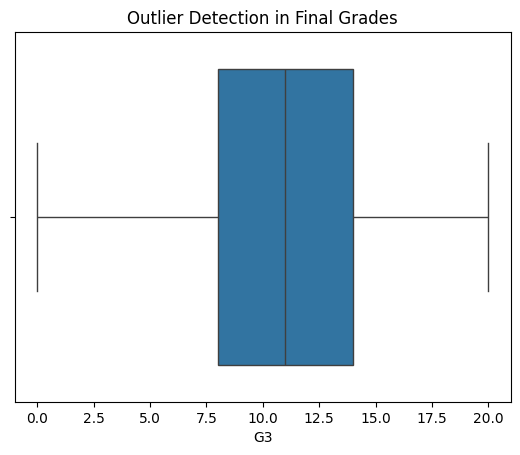

In [19]:
sns.boxplot(x=df["G3"])

plt.title("Outlier Detection in Final Grades")
plt.show()

Data preprocessing
Here:
- X = Independent variables (input features).
- y = Dependent variable (final grade).

In [20]:
X = df.drop("G3", axis=1)

y = df["G3"]

A. Handle categorical variables

We'll use One-Hot Encoding.

In [21]:
X = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

 Split training and testing data

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

Feature scaling

In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

Model training – Linear Regression

The general equation is:

Y = b_0+b_1X_1+b_2X_2+\cdots+b_nX_n


Where:
- Y = Predicted final grade.
- X = Input features.
- b = Model coefficients.
- b₀ = Intercept.

In [24]:
model = LinearRegression()

model.fit(
    X_train_scaled,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


Make predictions

In [25]:
y_pred = model.predict(X_test_scaled)

Compare actual and predicted values

In [26]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison.head(10)

,Actual,Predicted
0,10,6.001607
1,12,11.528478
2,5,2.866437
3,10,8.796631
4,9,8.553106
5,13,11.889641
6,18,19.096742
7,6,7.173079
8,0,7.405071
9,14,12.311537


Model evaluation

Metric	Interpretation

MAE	Average absolute prediction error

MSE	Average squared prediction error

RMSE	Error in the original score units

R²	Proportion of target variance explained by the model

MAE

In [27]:
mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 1.6466656197147496


Mean Squared Error (MSE)

In [28]:
mse = mean_squared_error(y_test, y_pred)

print("MSE:", mse)

MSE: 5.65664283323122


Root Mean Squared Error (RMSE)

In [29]:
rmse = np.sqrt(mse)

print("RMSE:", rmse)

RMSE: 2.3783697847961363


R² Score

In [30]:
r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)

R2 Score: 0.7241341236974023


Visualise model performance

Actual vs predicted grades

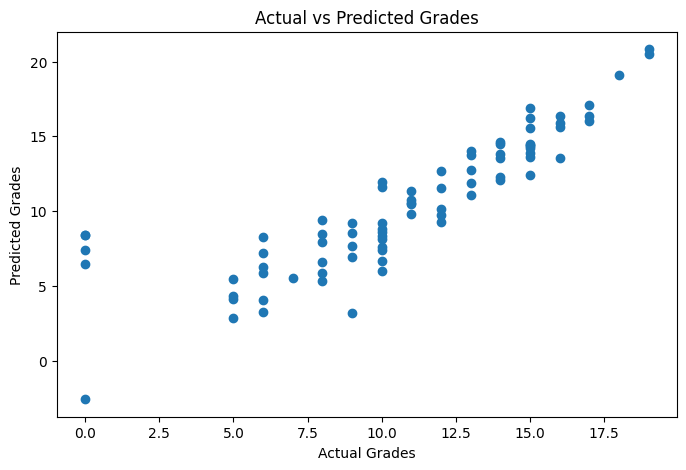

In [31]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")

plt.title("Actual vs Predicted Grades")

plt.show()

Regression residuals

Residual = Actual value − Predicted value.

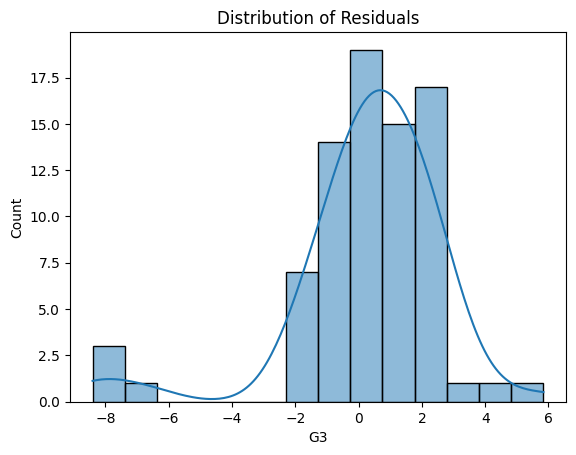

In [32]:
residuals = y_test - y_pred

sns.histplot(residuals, kde=True)

plt.title("Distribution of Residuals")

plt.show()

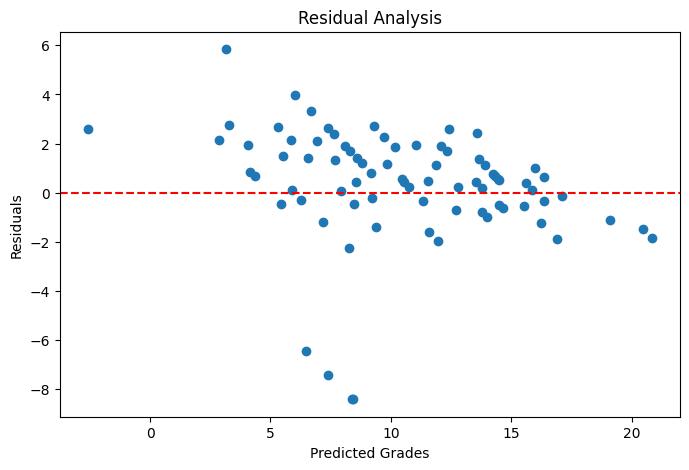

In [33]:
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Grades")
plt.ylabel("Residuals")

plt.title("Residual Analysis")

plt.show()

Compare with Decision Tree Regressor

In [34]:
dt_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train_scaled, y_train)

dt_pred = dt_model.predict(X_test_scaled)

In [35]:
print("Decision Tree MAE:",
      mean_absolute_error(y_test, dt_pred))

print("Decision Tree RMSE:",
      np.sqrt(mean_squared_error(y_test, dt_pred)))

print("Decision Tree R2:",
      r2_score(y_test, dt_pred))

Decision Tree MAE: 1.357218203737191
Decision Tree RMSE: 2.467248497769575
Decision Tree R2: 0.7031308891822728


comparison of linear regression and decision trees

In [36]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree"],
    "MAE": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, dt_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, dt_pred))
    ],
    "R2 Score": [
        r2_score(y_test, y_pred),
        r2_score(y_test, dt_pred)
    ]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.646666,2.378370,0.724134
1,Decision Tree,1.357218,2.467248,0.703131


In [37]:
import joblib

In [40]:
import os

print(os.getcwd())

d:\PYTHON\Student_Acedemic_Performance


In [41]:
import os
import joblib

# Create models folder
os.makedirs("models", exist_ok=True)

# Save models
joblib.dump(model, "models/student_model.pkl")

joblib.dump(scaler, "models/scaler.pkl")

joblib.dump(X.columns.tolist(), "models/features.pkl")

print("All models saved successfully!")

All models saved successfully!
